# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | Telco Customer Churn — https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv |
| что значит одна строка | 	Данные об одном клиенте телеком-компании |
| цель (столбец) | Churn |
| тип задачи | классификация  |
| метрика | доля верных ответов  |
| кому и зачем нужен такой прогноз | 	Например, команде по работе с клиентами- чтобы заранее находить тех, кто может уйти, и решать, кому предложить помощь или подходящий тариф |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
TARGET = "Churn"

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [3]:
raw = load_csv(DATA_URL)
print("Размер таблицы:", raw.shape)
raw.head()

Размер таблицы: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
passport(raw)

,тип,пропусков,"доля, %",разных,пример
customerID,object,0,0.0,7043,7590-VHVEG
gender,object,0,0.0,2,Female
SeniorCitizen,int64,0,0.0,2,0
Partner,object,0,0.0,2,Yes
Dependents,object,0,0.0,2,No
tenure,int64,0,0.0,73,1
PhoneService,object,0,0.0,2,No
MultipleLines,object,0,0.0,3,No phone service
InternetService,object,0,0.0,3,DSL
OnlineSecurity,object,0,0.0,3,No


In [5]:
print(raw[TARGET].value_counts(dropna=False))

raw[TARGET] = (raw[TARGET] == "Yes").astype(int)

print(raw[TARGET].value_counts())
log("цель Yes/No → 1/0", "Yes = 1, No = 0", len(raw))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
0    5174
1    1869
Name: count, dtype: int64


В таблице 7043 строки и 21 столбец. Каждая строка описывает одного клиента. Целевая колонка Churn показывает, ушёл клиент или остался: примерно 26,5% клиентов ушли, остальные остались. Я преобразовал значения цели в числа: Yes стало 1, No стало 0. Число строк при этом не изменилось. В паспорте данных видно, что TotalCharges хранится как текст, хотя в нём записаны суммы. По условию у 11 новых клиентов в этой колонке есть пустое значение; разберём его при очистке.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [6]:
print("Полных дублей:", raw.duplicated().sum())
print("Повторов customerID:", raw.duplicated(subset=["customerID"]).sum())

print("Строки с полными дублями:")
print(raw.loc[raw.duplicated(keep=False)].head(10))

print("Строки с повторяющимся customerID:")
print(raw.loc[raw.duplicated(subset=["customerID"], keep=False)].head(10))

Полных дублей: 0
Повторов customerID: 0
Строки с полными дублями:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []
Строки с повторяющимся customerID:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []


In [7]:
df = raw.copy()
log("дубли", "Полных дублей и повторов customerID нет; удалять нечего", len(df))

**Вывод.*Полных дублей и повторов customerID не найдено. Таблица с пустыми результатами означает, что совпадающих строк нет. Поэтому удалять нечего, оставляю все строки.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [8]:
def check_rules(d):
    return pd.DataFrame({
        "отрицательный срок обслуживания": d["tenure"] < 0,
        "отрицательная месячная плата": d["MonthlyCharges"] < 0,
        "SeniorCitizen не 0 и не 1": ~d["SeniorCitizen"].isin([0, 1]),
    })

In [9]:
flags = check_rules(df)
print("Нарушений по правилам:")
print(flags.sum())

print("Строки, где нарушено хотя бы одно правило:")
print(df.loc[flags.any(axis=1)].head(10))

Нарушений по правилам:
отрицательный срок обслуживания    0
отрицательная месячная плата       0
SeniorCitizen не 0 и не 1          0
dtype: int64
Строки, где нарушено хотя бы одно правило:
Empty DataFrame
Columns: [customerID, gender, SeniorCitizen, Partner, Dependents, tenure, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges, Churn]
Index: []


In [10]:
text_cols = df.select_dtypes(include="object").columns.drop(["customerID", "TotalCharges"])

for col in text_cols:
    print("\n", col)
    print(df[col].value_counts(dropna=False))

print("Пустых значений TotalCharges:", df["TotalCharges"].isna().sum())
print("Значений из одних пробелов в TotalCharges:",
      df["TotalCharges"].astype(str).str.strip().eq("").sum())

df.select_dtypes(include="number").describe()


 gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

 Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

 Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

 PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

 MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

 InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

 OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

 OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

 DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

 TechSupport
TechSupport
No   

,SeniorCitizen,tenure,MonthlyCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,0.265370
std,0.368612,24.559481,30.090047,0.441561
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,0.000000
50%,0.000000,29.000000,70.350000,0.000000
75%,0.000000,55.000000,89.850000,1.000000
max,1.000000,72.000000,118.750000,1.000000


In [11]:
log("проверки здравого смысла", "По трём правилам нарушений нет; строки не удалял.", len(df))
log("скрытые пропуски", "В TotalCharges найдено 11 значений из пробелов; No internet service и No phone service — реальные категории.", len(df))
show_journal()

,решение,строк
цель Yes/No → 1/0,"Yes = 1, No = 0",7043
дубли,Полных дублей и повторов customerID нет; удаля...,7043
проверки здравого смысла,По трём правилам нарушений нет; строки не удалял.,7043
скрытые пропуски,В TotalCharges найдено 11 значений из пробелов...,7043


**Вывод.**Проверил три правила: срок обслуживания не отрицательный, месячная плата не отрицательная, SeniorCitizen содержит только 0 и 1. Нарушений не найдено, строки не удалял. В TotalCharges нашёл 11 значений из пробелов — они означают пропуск, хотя обычная проверка их не видит. Категории No internet service и No phone service пропусками не считаю: они означают, что услуга не подключена. Пустые значения TotalCharges обработаю в следующем разделе.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [12]:
blank_total = df["TotalCharges"].astype(str).str.strip().eq("")
print("Пустых значений-пробелов в TotalCharges:", blank_total.sum())
print(df.loc[blank_total, ["tenure", "MonthlyCharges", "TotalCharges", TARGET]])

df.loc[blank_total, "TotalCharges"] = pd.NA

missing = df.isna().sum()
print("Пропуски по столбцам:")
print(missing[missing > 0])

Пустых значений-пробелов в TotalCharges: 11
      tenure  MonthlyCharges TotalCharges  Churn
488        0           52.55                   0
753        0           20.25                   0
936        0           80.85                   0
1082       0           25.75                   0
1340       0           56.05                   0
3331       0           19.85                   0
3826       0           25.35                   0
4380       0           20.00                   0
5218       0           19.70                   0
6670       0           73.35                   0
6754       0           61.90                   0
Пропуски по столбцам:
TotalCharges    11
dtype: int64


In [13]:
df.groupby(df["TotalCharges"].isna())[TARGET].agg(["mean", "size"])

,mean,size
TotalCharges,,
False,0.265785,7032
True,0.000000,11


In [14]:
df["TotalCharges_was_missing"] = df["TotalCharges"].isna().astype(int)
df["TotalCharges"] = df["TotalCharges"].fillna("0")

log("TotalCharges", "11 пропусков при tenure=0; добавил флаг и заполнил нулём", len(df))
show_journal()

,решение,строк
цель Yes/No → 1/0,"Yes = 1, No = 0",7043
дубли,Полных дублей и повторов customerID нет; удаля...,7043
проверки здравого смысла,По трём правилам нарушений нет; строки не удалял.,7043
скрытые пропуски,В TotalCharges найдено 11 значений из пробелов...,7043
TotalCharges,11 пропусков при tenure=0; добавил флаг и запо...,7043


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
|  |  |  |  |  |
| TotalCharges | 11 | 	Нет накопленных начислений у новых клиентов |Создаём флаг, заполняем нулём | Во всех 11 строках tenure = 0 |

**Вывод.** Нашёл 11 пропусков в TotalCharges; все относятся к клиентам с tenure = 0. Отметил их отдельным флагом и заполнил нулём как отсутствие накопленных начислений. У остальных столбцов пропусков не обнаружено

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [15]:
total_before = df["TotalCharges"].copy()
total_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Пропусков после преобразования:", total_numeric.isna().sum())
print("Значения, которые не удалось преобразовать:")
print(total_before[total_numeric.isna()].head(10))

df["TotalCharges"] = total_numeric
print("Типы столбцов:")
print(df.dtypes)

Пропусков после преобразования: 0
Значения, которые не удалось преобразовать:
Series([], Name: TotalCharges, dtype: object)
Типы столбцов:
customerID                   object
gender                       object
SeniorCitizen                 int64
Partner                      object
Dependents                   object
tenure                        int64
PhoneService                 object
MultipleLines                object
InternetService              object
OnlineSecurity               object
OnlineBackup                 object
DeviceProtection             object
TechSupport                  object
StreamingTV                  object
StreamingMovies              object
Contract                     object
PaperlessBilling             object
PaymentMethod                object
MonthlyCharges              float64
TotalCharges                float64
Churn                         int64
TotalCharges_was_missing      int64
dtype: object


In [16]:
print("В датасете Telco нет столбцов с датой или временем.")

В датасете Telco нет столбцов с датой или временем.


**Вывод.** TotalCharges был записан текстом. Я преобразовал его в числовой тип; новых пропусков после преобразования не появилось. Столбцов с датой или временем в датасете нет.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [17]:
columns_to_check = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in columns_to_check:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    is_outlier = (df[col] < lower) | (df[col] > upper)

    print(
        f"{col}: границы от {lower:.2f} до {upper:.2f}; "
        f"кандидатов: {is_outlier.sum()}"
    )

tenure: границы от -60.00 до 124.00; кандидатов: 0
MonthlyCharges: границы от -46.02 до 171.38; кандидатов: 0
TotalCharges: границы от -4683.52 до 8868.67; кандидатов: 0


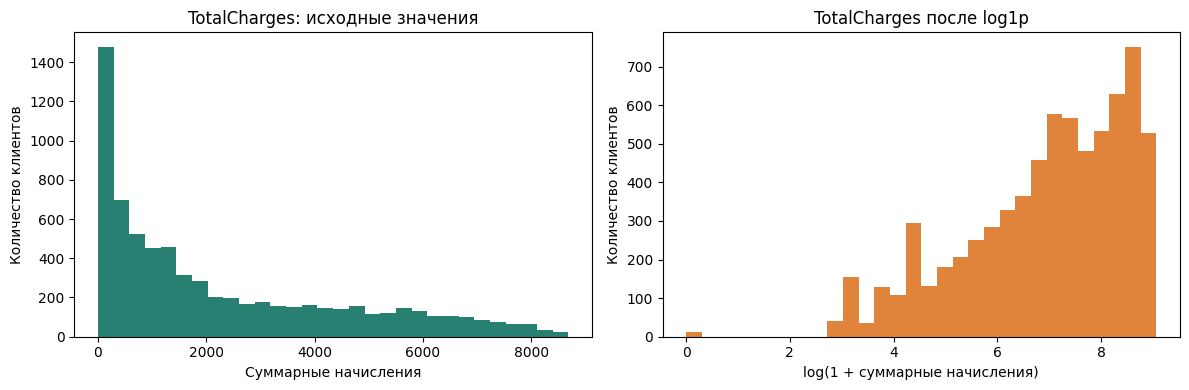

,решение,строк
цель Yes/No → 1/0,"Yes = 1, No = 0",7043
дубли,Полных дублей и повторов customerID нет; удаля...,7043
проверки здравого смысла,По трём правилам нарушений нет; строки не удалял.,7043
скрытые пропуски,В TotalCharges найдено 11 значений из пробелов...,7043
TotalCharges,11 пропусков при tenure=0; добавил флаг и запо...,7043
выбросы,По IQR кандидатов нет. TotalCharges имеет длин...,7043


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["TotalCharges"], bins=30, color=TEAL)
axes[0].set_title("TotalCharges: исходные значения")
axes[0].set_xlabel("Суммарные начисления")
axes[0].set_ylabel("Количество клиентов")

axes[1].hist(np.log1p(df["TotalCharges"]), bins=30, color=ORANGE)
axes[1].set_title("TotalCharges после log1p")
axes[1].set_xlabel("log(1 + суммарные начисления)")
axes[1].set_ylabel("Количество клиентов")

plt.tight_layout()
plt.show()
log(
    "выбросы",
    "По IQR кандидатов нет. TotalCharges имеет длинный правый хвост; значения оставляю, не удаляю и не обрезаю. log1p применён только для сравнения графиков.",
    len(df),
)
show_journal()

**Вывод.** По правилу IQR кандидатов на выбросы в tenure, MonthlyCharges и TotalCharges не найдено. У TotalCharges заметен длинный хвост вправо: высокие значения считаю возможными накопленными начислениями, а не ошибками. Строки и значения не удалял и не обрезал. Сравнил исходное распределение с log1p; логарифмирование пока использовал только на графике.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

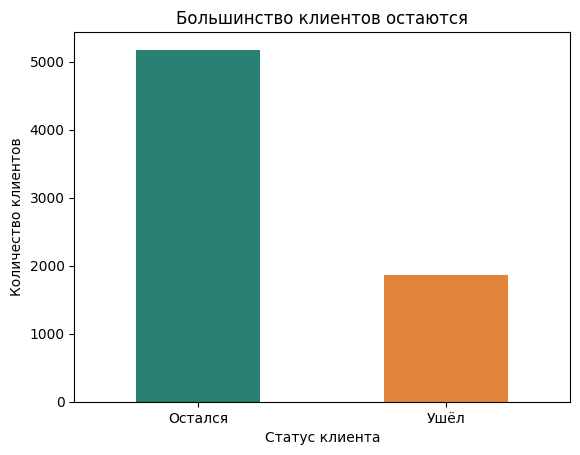

In [19]:
churn_labels = df[TARGET].map({0: "Остался", 1: "Ушёл"})
churn_counts = churn_labels.value_counts().reindex(["Остался", "Ушёл"])

ax = churn_counts.plot(kind="bar", color=[TEAL, ORANGE])
ax.set_title("Большинство клиентов остаются")
ax.set_xlabel("Статус клиента")
ax.set_ylabel("Количество клиентов")
plt.xticks(rotation=0)
plt.show()

**Что видно на графике 1.** Большинство клиентов остались: 5174 человека, около 73,5%. Ушли 1869 человек, около 26,5%. Значит, классы распределены не поровну; позже важно сравнить модель с простым вариантом, который всегда предсказывает самый частый класс.

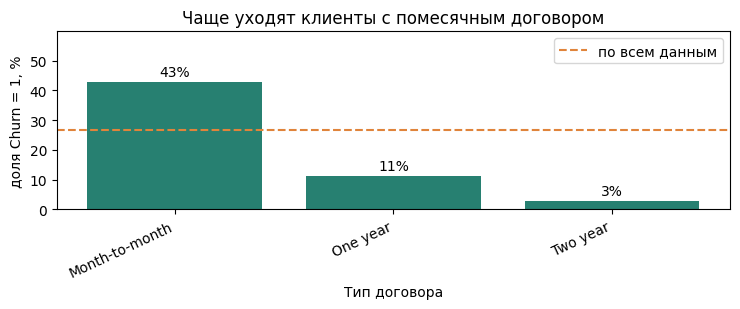

,mean,size
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


In [20]:
target_plot(
    df,
    "Contract",
    TARGET,
    "Чаще уходят клиенты с помесячным договором",
    "Тип договора",
)

**Что видно на графике 2.** Доля ушедших клиентов снижается с увеличением срока договора: 42,7% у клиентов с помесячным договором, 11,3% с договором на год и 2,8% на два года. Это связь между типом договора и уходом клиента, но график сам по себе не доказывает, что именно договор вызывает уход или удержание.

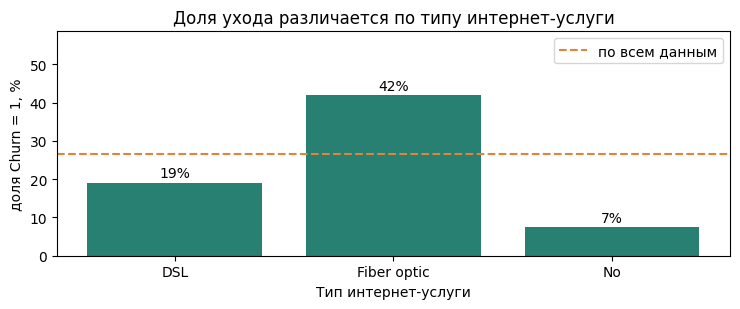

,mean,size
InternetService,,
DSL,0.190,2421
Fiber optic,0.419,3096
No,0.074,1526


In [21]:
target_plot(
    df,
    "InternetService",
    TARGET,
    "Доля ухода различается по типу интернет-услуги",
    "Тип интернет-услуги",
)

**Что видно на графике 3.** ...

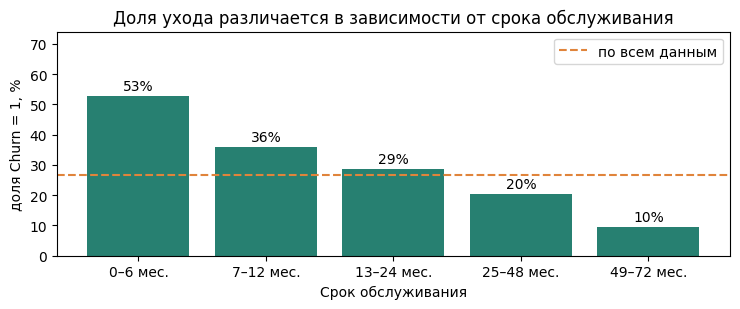

,mean,size
tenure,,
0–6 мес.,0.529,1481
7–12 мес.,0.359,705
13–24 мес.,0.287,1024
25–48 мес.,0.204,1594
49–72 мес.,0.095,2239


In [22]:
tenure_group = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6 мес.", "7–12 мес.", "13–24 мес.", "25–48 мес.", "49–72 мес."],
)

target_plot(
    df,
    tenure_group,
    TARGET,
    "Доля ухода различается в зависимости от срока обслуживания",
    "Срок обслуживания",
)

**Что видно на графике 4.** Доля ушедших постепенно снижается с ростом срока обслуживания: 52,9% в первые 0–6 месяцев, 35,9% за 7–12 месяцев и 9,5% за 49–72 месяца. Это заметная связь срока обслуживания с уходом клиента, но она сама по себе не доказывает причинность.

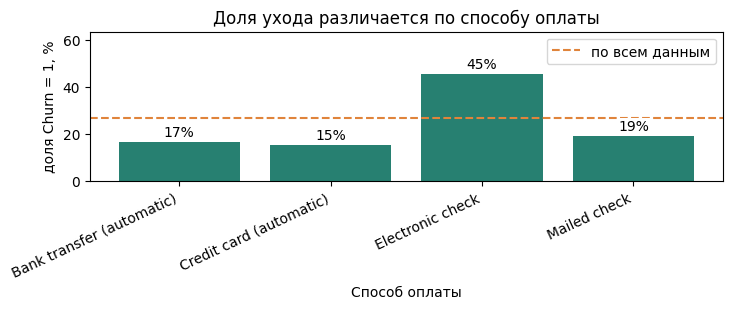

,mean,size
PaymentMethod,,
Bank transfer (automatic),0.167,1544
Credit card (automatic),0.152,1522
Electronic check,0.453,2365
Mailed check,0.191,1612


In [23]:
target_plot(
    df,
    "PaymentMethod",
    TARGET,
    "Доля ухода различается по способу оплаты",
    "Способ оплаты",
)

**Что видно на графике 5.** Доля ушедших клиентов с оплатой электронным чеком — 45,3%, это выше, чем при остальных способах оплаты. Например, для автоматической оплаты кредитной картой доля составляет 15,2%. По графику нельзя заключить, что способ оплаты вызывает уход клиента.

**Вывод по EDA.** В целом ушли около 26,5% клиентов.
При помесячном договоре ушли 42,7%, при договоре на два года — 2,8%.
Среди клиентов со стажем 0–6 месяцев ушли 52,9%, а со стажем 49–72 месяца — 9,5%.
Для Fiber optic доля ухода — 41,9%, для клиентов без интернет-услуги — 7,4%.
Среди пользователей электронного чека доля ухода — 45,3%; это самая высокая доля среди показанных способов оплаты.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [24]:
def clean(raw_table):
    d = raw_table.copy()

    if d[TARGET].dtype == "object":
        d[TARGET] = (d[TARGET] == "Yes").astype(int)

    d = d.drop_duplicates()

    blank_total = d["TotalCharges"].astype(str).str.strip().eq("")
    d["TotalCharges_was_missing"] = blank_total.astype(int)
    d.loc[blank_total, "TotalCharges"] = "0"
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")

    return d

In [25]:
clean_df = clean(raw)

print("Совпадает с пошаговой очисткой:", clean_df.equals(df))

assert clean_df.equals(df)
assert clean_df.isna().sum().sum() == 0
assert check_rules(clean_df).sum().sum() == 0
assert not clean_df.duplicated().any()

print("Все проверки пройдены")

Совпадает с пошаговой очисткой: True
Все проверки пройдены


In [26]:
show_journal()

,решение,строк
цель Yes/No → 1/0,"Yes = 1, No = 0",7043
дубли,Полных дублей и повторов customerID нет; удаля...,7043
проверки здравого смысла,По трём правилам нарушений нет; строки не удалял.,7043
скрытые пропуски,В TotalCharges найдено 11 значений из пробелов...,7043
TotalCharges,11 пропусков при tenure=0; добавил флаг и запо...,7043
выбросы,По IQR кандидатов нет. TotalCharges имеет длин...,7043


In [27]:

Path("data").mkdir(exist_ok=True)
clean_df.to_csv("data/telco_clean.csv", index=False)
print("Сохранил data/telco_clean.csv")

Сохранил data/telco_clean.csv


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [28]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 7043, стало 7043; столбцов: было 21, стало 22


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

In [29]:
# ПОМОЩНИКИ ЭТАПА 2. Запустите после ячейки «Помощники» этапа 1.
import joblib
import sklearn
from sklearn.compose import make_column_transformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, TargetEncoder


def is_class(y):
    """Цель 0 и 1: классификация. Иначе регрессия."""
    return set(pd.Series(y).dropna().unique()) <= {0, 1}


def make_prep(num_cols, cat_cols=(), flag_cols=(), add_features=None, min_frequency=10, target_cols=(), y=None):
    """Вся подготовка одним объектом, как в части 5 практики занятия 12.

    num_cols: числа, заполняются медианой train и стандартизируются;
    flag_cols: флаги 0 и 1, идут как есть;
    cat_cols: категории, флаги через OneHotEncoder, редкие реже min_frequency в общий столбец;
    target_cols: категории с сотнями значений, кодирование по цели через TargetEncoder (нужен y);
    add_features: ваша функция признаков по одной строке, станет первым шагом.
    """
    branches = [(make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), list(num_cols))]
    if flag_cols:
        branches.append(("passthrough", list(flag_cols)))
    if cat_cols:
        branches.append((OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                       sparse_output=False), list(cat_cols)))
    if target_cols:
        branches.append((make_target_encoder(y), list(target_cols)))
    steps = [FunctionTransformer(add_features)] if add_features is not None else []
    return make_pipeline(*steps, make_column_transformer(*branches))


def make_target_encoder(y):
    """TargetEncoder с одинаковым результатом на любой версии scikit-learn."""
    version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
    folds = StratifiedKFold if is_class(y) else KFold
    if version >= (1, 9):
        return TargetEncoder(cv=folds(5, shuffle=True, random_state=0))
    return TargetEncoder(random_state=0)


def make_model(prep, y):
    """Подготовка и простая модель в одном Pipeline: логистическая регрессия для классов, линейная для чисел."""
    model = LogisticRegression(solver="newton-cholesky") if is_class(y) else LinearRegression()
    return make_pipeline(prep, model)


def make_dummy(y):
    """Пустышка: самый частый класс или медиана."""
    return DummyClassifier(strategy="most_frequent") if is_class(y) else DummyRegressor(strategy="median")


def cv_score(model, X, y):
    """Кросс-валидация на train: доля верных для классов, MAE для чисел."""
    if is_class(y):
        return cross_val_score(model, X, y, cv=5, scoring="accuracy").mean()
    return -cross_val_score(model, X, y, cv=5, scoring="neg_mean_absolute_error").mean()


def test_score(model, X_test, y_test):
    """Оценка на test: доля верных для классов, MAE для чисел. Вызывать один раз в конце."""
    prediction = model.predict(X_test)
    if is_class(y_test):
        return accuracy_score(y_test, prediction)
    return mean_absolute_error(y_test, prediction)


def ladder_plot(ladder, y, path=None):
    """График-лестница: пустышка первой ступенью. Заголовок-вывод считается сам."""
    names, values = list(ladder.index), list(ladder.values)
    if is_class(y):
        title = f"Модель лучше пустышки на {(max(values) - values[0]) * 100:.1f} процентного пункта"
        ylabel, fmt, low = "доля верных", "%.3f", 0.5 if min(values) > 0.5 else 0
    else:
        title = f"Модель ошибается на {(1 - min(values) / values[0]) * 100:.0f}% меньше пустышки"
        ylabel, fmt, low = "MAE, меньше лучше", "%.2f", 0
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    colors = [GRAY] + [TEAL] * (len(values) - 1)
    bars = ax.bar(names, values, color=colors)
    ax.bar_label(bars, fmt=fmt, padding=2)
    ax.set_ylim(low, max(values) * 1.12)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(names) > 4:
        plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    if path is not None:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=120)
    plt.show()


def write_requirements(path="requirements.txt"):
    """requirements.txt с версиями библиотек этой среды."""
    import matplotlib
    lines = [f"pandas=={pd.__version__}", f"numpy=={np.__version__}", f"scikit-learn=={sklearn.__version__}",
             f"matplotlib=={matplotlib.__version__}", f"joblib=={joblib.__version__}"]
    Path(path).write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n".join(lines))


print("помощники этапа 2 готовы")

помощники этапа 2 готовы


---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [30]:
def add_features(d):
    """Добавляет признаки по каждой строке клиента."""
    out = d.copy()

    addon_cols = [
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
    ]

    out["internet_addon_count"] = d[addon_cols].eq("Yes").sum(axis=1)
    out["is_month_to_month"] = (d["Contract"] == "Month-to-month").astype(int)
    out["is_new_customer"] = (d["tenure"] <= 12).astype(int)

    return out


add_features(clean_df.head(3))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalCharges_was_missing,internet_addon_count,is_month_to_month,is_new_customer
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,1,1,1
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,0,2,0,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0,2,1,1


| Признак | Зачем нужен |
|---|---|
| `internet_addon_count` | Помогает проверить, связана ли численность дополнительных услуг с уходом клиента. |
| `is_month_to_month` | Помогает проверить, чаще ли уходят клиенты с помесячным договором. |
| `is_new_customer` | Помогает проверить, отличается ли уход клиентов со стажем до 12 месяцев. |

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [31]:
num_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "internet_addon_count",
]

flag_cols = [
    "SeniorCitizen",
    "TotalCharges_was_missing",
    "is_month_to_month",
    "is_new_customer",
]

cat_cols = [
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
]

prep = make_prep(
    num_cols,
    cat_cols,
    flag_cols,
    add_features=add_features,
)

Вывод по разделу 11. Использованы 15 категориальных столбцов. Порог редкости — 10 наблюдений. После подготовки получено 49 числовых признаков без пропусков.

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

| Столбец | Когда известен | Решение |
|---|---|---|
| `Churn` | Это ответ, который хотим предсказать | Не включать в признаки |
| `customerID` | Идентификатор клиента | Не включать: это номер, а не описание клиента |
| `TotalCharges` | Сумма начислений за время обслуживания; точный момент её фиксации в этой таблице не указан | Проверить модель с этим столбцом и без него |

In [32]:
leaks = []

inputs = [
    column
    for column in clean_df.columns
    if column not in leaks + [TARGET, "customerID"]
]

X = clean_df[inputs]
y = clean_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print("Вся таблица признаков:", X.shape)
print("Обучающая часть:", X_train.shape)
print("Тестовая часть:", X_test.shape)
print("Доля ушедших в train и test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Вся таблица признаков: (7043, 20)
Обучающая часть: (5634, 20)
Тестовая часть: (1409, 20)
Доля ушедших в train и test: 0.265 0.265


In [33]:
num_cols_without_total = [
    column for column in num_cols
    if column != "TotalCharges"
]

prep_without_total = make_prep(
    num_cols_without_total,
    cat_cols,
    flag_cols,
    add_features=add_features,
)

score_without_total = cv_score(
    make_model(prep_without_total, y),
    X_train,
    y_train,
)

score_with_total = cv_score(
    make_model(prep, y),
    X_train,
    y_train,
)

print("Без TotalCharges:", round(score_without_total, 3))
print("С TotalCharges:  ", round(score_with_total, 3))

Без TotalCharges: 0.806
С TotalCharges:   0.807


In [34]:
Z_train = prep.fit_transform(X_train)

print("Размер после подготовки:", Z_train.shape)
print("Пропусков:", int(np.isnan(Z_train).sum()))

Размер после подготовки: (5634, 49)
Пропусков: 0


Проверка TotalCharges. Точность модели без этого признака — 0,806, с ним — 0,807. Заметного скачка качества нет. В наборе не указано, когда зафиксирована сумма начислений, поэтому время её доступности остаётся неясным.

## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

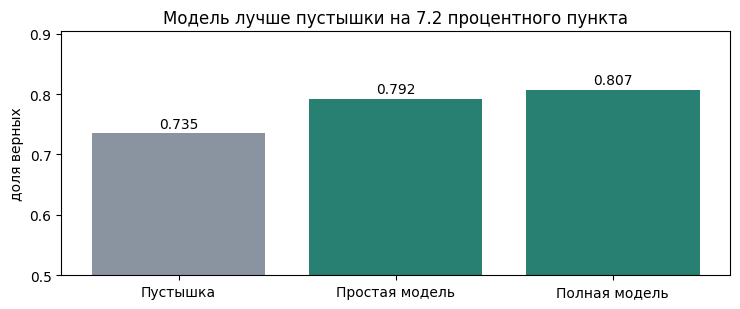

In [35]:
few_prep = make_prep(
    ["tenure", "MonthlyCharges"],
    ["Contract"],
    ["SeniorCitizen"],
    add_features=add_features,
)

full_prep = make_prep(
    num_cols,
    cat_cols,
    flag_cols,
    add_features=add_features,
)

ladder = pd.Series({
    "Пустышка": cv_score(make_dummy(y), X_train, y_train),
    "Простая модель": cv_score(
        make_model(few_prep, y),
        X_train,
        y_train,
    ),
    "Полная модель": cv_score(
        make_model(full_prep, y),
        X_train,
        y_train,
    ),
})

ladder_plot(ladder, y, path="figures/baseline.png")

In [36]:
final_model = make_model(full_prep, y)
final_model.fit(X_train, y_train)

dummy_model = make_dummy(y)
dummy_model.fit(X_train, y_train)

dummy_test_score = test_score(dummy_model, X_test, y_test)
full_test_score = test_score(final_model, X_test, y_test)

print("Test, пустышка:", round(dummy_test_score, 3))
print("Test, полная модель:", round(full_test_score, 3))
print(
    "Разница:",
    round((full_test_score - dummy_test_score) * 100, 1),
    "процентного пункта",
)

Test, пустышка: 0.735
Test, полная модель: 0.802
Разница: 6.7 процентного пункта


Вывод по моделям. На кросс-валидации пустышка показала 0,735, простая модель — 0,792, полная — 0,807. На тестовой выборке пустышка показала 0,735, полная модель — 0,802. На test полная модель лучше пустышки на 6,7 процентного пункта. Результат теста близок к кросс-валидации: 0,802 против 0,807.

## 14. Выводы
В датасете 7043 клиента; ушли 1869 (26,5%). Полных дублей не нашлось. У 11 клиентов с нулевым стажем TotalCharges был пустым; в очистке я сохранил этот факт отдельным флагом и заменил пустое значение на 0.
Подготовка создала 49 признаков для обучающих данных; в итоговой таблице 0 пропусков. Для редких категорий использован порог min_frequency=10.
Доля ухода у клиентов с помесячным договором — 42,7%, с договором на два года — 2,8%. Среди клиентов со стажем 0–6 месяцев она составила 52,9%, а со стажем 49–72 месяца — 9,5%. Это различия в данных, они сами по себе не доказывают причину ухода.
На тестовой выборке полная модель показала точность 0,802, пустышка — 0,735; разница — 6,7 процентного пункта. Следующим шагом я бы проверил, сколько ушедших клиентов модель находит, потому что одной общей точности недостаточно для полной оценки.


## 15. README

По шаблону из ТЗ. Журнал и результаты удобно собрать из переменных тетради. Пример: часть 9, раздел 9.4.

In [37]:
journal_rows = "\n".join(
    f"| {step} | {row['решение']} | {row['строк']} |"
    for step, row in journal.items()
)

ladder_rows = "\n".join(
    f"| {name} | {value:.3f} |"
    for name, value in ladder.items()
)

gain_test = (full_test_score - dummy_test_score) * 100

conclusions = [
    f"В таблице {len(raw)} клиентов; ушли {int(raw[TARGET].sum())} ({raw[TARGET].mean():.1%}).",
    "Полных дублей не найдено; 11 пустых значений TotalCharges были у клиентов со стажем 0 месяцев.",
    "Уход составил 42,7% при помесячном договоре и 2,8% при договоре на два года.",
    f"На test полная модель показала {full_test_score:.3f} против {dummy_test_score:.3f} у пустышки.",
    "Дальше стоит проверить, сколько ушедших клиентов модель находит, а не только общую точность.",
]

conclusion_rows = "\n".join(f"* {line}" for line in conclusions)

readme = f"""# Почему клиенты уходят из телеком-компании?

**Задача.** Предсказать, уйдёт ли клиент (`Churn`). Это задача классификации; основная метрика — доля верных ответов (`accuracy`).

**Данные.** [Telco Customer Churn от IBM]({DATA_URL}). В исходной таблице {raw.shape[0]} строк и {raw.shape[1]} столбцов; одна строка описывает одного клиента.

## Что сделано с данными

| шаг | решение | строк |
|---|---|---|
{journal_rows}

## Главное из EDA

* Уход составил 42,7% при помесячном договоре и 2,8% при договоре на два года.
* Среди клиентов со стажем 0–6 месяцев ушли 52,9%; со стажем 49–72 месяца — 9,5%.
* [График сравнения моделей](figures/baseline.png)

## Признаки

После подготовки получилось {Z_train.shape[1]} числовых признаков, пропусков нет. Порог объединения редких категорий — 10 наблюдений.

## Утечка

`Churn` — целевой столбец, поэтому он не входит в признаки. `customerID` исключён как идентификатор. Для `TotalCharges` сравнили модель с этим столбцом и без него: {score_with_total:.3f} и {score_without_total:.3f}. Резкого скачка качества нет; точный момент фиксации начислений в данных не указан.

## Результаты

Кросс-валидация на обучающих данных:

| модель | доля верных ответов |
|---|---:|
{ladder_rows}

На test: пустышка — {dummy_test_score:.3f}, полная модель — {full_test_score:.3f}. Разница — {gain_test:.1f} процентного пункта.

## Выводы

{conclusion_rows}

## Как запустить

1. Установить библиотеки: `pip install -r requirements.txt`.
2. Открыть `project.ipynb` и выполнить ячейки сверху вниз. Сырые данные загрузятся по ссылке из проекта.
"""

Path("README.md").write_text(readme, encoding="utf-8")
print(readme)

# Почему клиенты уходят из телеком-компании?

**Задача.** Предсказать, уйдёт ли клиент (`Churn`). Это задача классификации; основная метрика — доля верных ответов (`accuracy`).

**Данные.** [Telco Customer Churn от IBM](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv). В исходной таблице 7043 строк и 21 столбцов; одна строка описывает одного клиента.

## Что сделано с данными

| шаг | решение | строк |
|---|---|---|
| цель Yes/No → 1/0 | Yes = 1, No = 0 | 7043 |
| дубли | Полных дублей и повторов customerID нет; удалять нечего | 7043 |
| проверки здравого смысла | По трём правилам нарушений нет; строки не удалял. | 7043 |
| скрытые пропуски | В TotalCharges найдено 11 значений из пробелов; No internet service и No phone service — реальные категории. | 7043 |
| TotalCharges | 11 пропусков при tenure=0; добавил флаг и заполнил нулём | 7043 |
| выбросы | По IQR кандидатов нет. TotalCharges имеет длинный правый хвост; значения оставл

## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.

In [38]:
write_requirements()

pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0
joblib==1.6.0
